# DRG tutorial: registering 4D radar scans with Doppler and RCS

This notebook walks through the six stages of DRG on one pair of consecutive radar scans, then
registers a whole window of 30 pairs and checks the result against the estimates of the paper.

**Data** (`example/data`, 3 MB): 31 consecutive scans of the NTU4DRadLM sequence *loop3*
(car, about 7.5 m/s, Oculii Eagle at 12 Hz). This is the windowed set *loop3 set 4*
(frames 5692 to 5722) of the paper, and the files are exactly the clouds the paper registered.
Every return has five values: x, y, z [m], RCS [dB] and Doppler [m/s] (the raw signed range rate).
The ground truth is an excerpt of the dataset's `gt_odom.txt`.

| Stage | | Code |
|---|---|---|
| 1 | Soft-REVE ego-velocity, Doppler residual $e_i$ and confidence $w_i$ | `drg/ego_velocity.py` |
| 2 | 37-D descriptor: FPFH + [RCS, $w_i$, neighbour count, height] | `drg/descriptor.py` |
| 3 | mutual nearest neighbours in descriptor space | `drg/correspondence.py` |
| 4 | Doppler–RCS gate: $\lvert\Delta\rho\rvert \le 1$ dB and $\lvert\Delta e\rvert \le 0.01$ m/s | `drg/correspondence.py` |
| 5 | correspondence RANSAC + truncated-Cauchy IRLS: $\mathbf R$, $\mathbf t_{geo}$ | `drg/solver.py` |
| 6 | Doppler fusion $\mathbf t = \omega\,\mathbf t_{dop} + (1-\omega)\,\mathbf t_{geo}$ | `drg/fusion.py` |

In [1]:
import os
import sys

# Every number in the paper was computed single-threaded. This must be set before numpy is imported.
os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))

import json

import matplotlib.pyplot as plt
import numpy as np

from drg import DRG, DRGParams, NormStats
from drg.correspondence import doppler_rcs_gate, mutual_nearest_neighbours
from drg.ego_velocity import doppler_residual, soft_reve
from drg.evaluation import GroundTruth, pose_error
from drg.io import DumpSequence
from drg.sequence import register_pairs

seq = DumpSequence("data/loop3_set4")               # one folder per scan: cloud.pcd + stamp
gt = GroundTruth("data/loop3_gt_odom_excerpt.txt")  # TUM format, 10 Hz
params = DRGParams()                                 # the paper's values (= config/drg.yaml)
drg = DRG(params, NormStats.from_yaml("../config/norm_stats/loop3.yaml"))

frames = seq.indices()
print(f"{len(frames)} scans, frames {frames[0]}-{frames[-1]}, "
      f"{seq.stamp(frames[-1]) - seq.stamp(frames[0]):.2f} s")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


31 scans, frames 5692-5722, 2.49 s


## A 4D radar scan

The *target* is the earlier scan and the *source* the later one. DRG estimates the transform
$\mathbf T$ that maps source points into the target frame. The axes are x forward, y left, z up,
with the origin at the radar.

target 5692: 3377 returns, source 5693: 3310 returns, dt = 63.8 ms
x, y, z [m], RCS [dB], Doppler [m/s] of the first three returns:
[[ 4.019  2.26  -1.372  7.05  -6.716]
 [ 4.009  2.537 -1.342 10.05  -6.44 ]
 [ 4.518  2.452 -1.32  15.6   -6.746]]


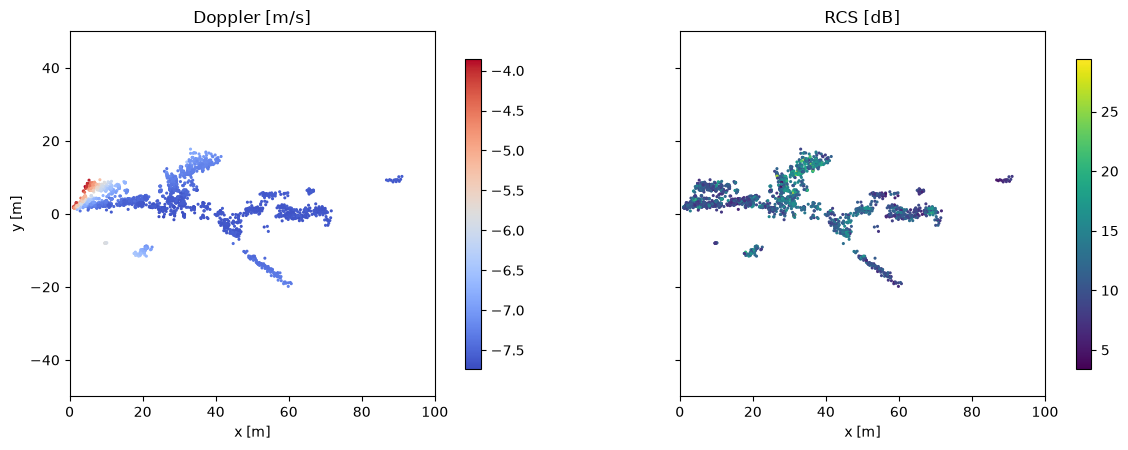

In [2]:
k_t, k_s = frames[0], frames[1]
scan_t, scan_s = seq.points(k_t), seq.points(k_s)
dt = seq.stamp(k_s) - seq.stamp(k_t)
print(f"target {k_t}: {len(scan_t)} returns, source {k_s}: {len(scan_s)} returns, dt = {1000 * dt:.1f} ms")
print("x, y, z [m], RCS [dB], Doppler [m/s] of the first three returns:")
print(np.round(scan_t[:3], 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, col, title, cmap in [(axes[0], 4, "Doppler [m/s]", "coolwarm"), (axes[1], 3, "RCS [dB]", "viridis")]:
    sc = ax.scatter(scan_t[:, 0], scan_t[:, 1], c=scan_t[:, col], s=1.5, cmap=cmap)
    ax.set(xlim=(0, 100), ylim=(-50, 50), xlabel="x [m]", title=title, aspect="equal")
    fig.colorbar(sc, ax=ax, shrink=0.85)
axes[0].set_ylabel("y [m]")
plt.tight_layout()
plt.show()

## Stage 1 — Soft-REVE: ego-velocity from Doppler

A static return seen from a radar moving with velocity $\mathbf v$ has Doppler
$d_i = -\mathbf n_i^\top \mathbf v$, with $\mathbf n_i$ the unit direction of the return.
REVE fits $\mathbf v$ by three-point RANSAC and least squares. Soft-REVE keeps that fit and gives
every return its residual $e_i = d_i + \mathbf n_i^\top\hat{\mathbf v}$ (about zero for a static
return) and a confidence $w_i = \exp(-e_i^2 / 2\sigma^2)$, instead of discarding outliers.

Soft-REVE ego-velocity  [7.657 0.16  0.033] m/s, |v| = 7.66 m/s
ground truth (approx.)  [ 7.599 -0.094  0.32 ] m/s, |v| = 7.61 m/s
3377 returns kept, 3.8 % with confidence w < 0.5


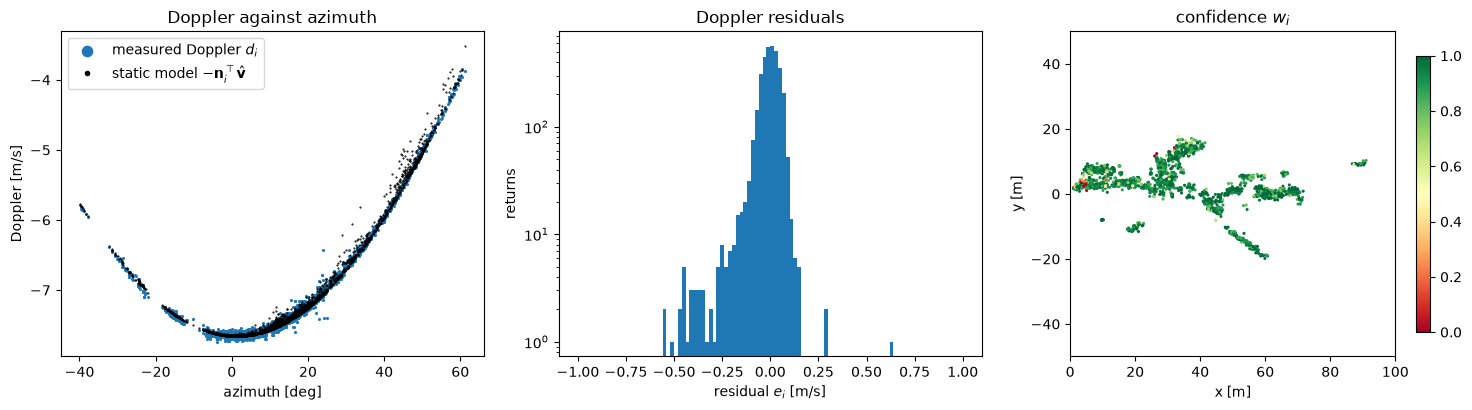

In [3]:
kept, v_hat, w = soft_reve(scan_t, params, params.seed)
e = doppler_residual(kept, v_hat)

T_gt = gt.relative(seq.stamp(k_t), seq.stamp(k_s))   # ground truth, used only for comparison
v_gt = T_gt[:3, 3] / dt                              # mean velocity between the two scans
print(f"Soft-REVE ego-velocity  {np.round(v_hat, 3)} m/s, |v| = {np.linalg.norm(v_hat):.2f} m/s")
print(f"ground truth (approx.)  {np.round(v_gt, 3)} m/s, |v| = {np.linalg.norm(v_gt):.2f} m/s")
print(f"{len(kept)} returns kept, {100 * np.mean(w < 0.5):.1f} % with confidence w < 0.5")

azimuth = np.degrees(np.arctan2(kept[:, 1], kept[:, 0]))
order = np.argsort(azimuth)
predicted = -(kept[:, :3] / np.linalg.norm(kept[:, :3], axis=1, keepdims=True)) @ v_hat

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].scatter(azimuth, kept[:, 4], s=1.5, c="tab:blue", label="measured Doppler $d_i$")
axes[0].plot(azimuth[order], predicted[order], ".", ms=1, c="k", label=r"static model $-\mathbf{n}_i^\top\hat{\mathbf{v}}$")
axes[0].set(xlabel="azimuth [deg]", ylabel="Doppler [m/s]", title="Doppler against azimuth")
axes[0].legend(markerscale=6, loc="upper left")
axes[1].hist(e, bins=np.linspace(-1, 1, 101), color="tab:blue", log=True)
axes[1].set(xlabel="residual $e_i$ [m/s]", ylabel="returns", title="Doppler residuals")
sc = axes[2].scatter(kept[:, 0], kept[:, 1], c=w, s=1.5, cmap="RdYlGn", vmin=0, vmax=1)
axes[2].set(xlim=(0, 100), ylim=(-50, 50), xlabel="x [m]", ylabel="y [m]", title="confidence $w_i$", aspect="equal")
fig.colorbar(sc, ax=axes[2], shrink=0.85)
plt.tight_layout()
plt.show()

## Stage 2 — the 37-D descriptor

Each return is described by its 33-D FPFH (local shape) and four z-scored radar channels:
RCS $\rho_i$, confidence $w_i$, the number of neighbours within 0.3 m and the height $z_i$.
The two blocks are L2-normalised and weighted equally. `prepare` runs stages 1 and 2 once per scan.

In [4]:
target = drg.prepare(scan_t)
source = drg.prepare(scan_s)
print("target descriptor:", target.descriptor.shape, " source descriptor:", source.descriptor.shape)
print("ego-velocity of the source scan:", np.round(source.velocity, 3), "m/s")

target descriptor: (3377, 37)  source descriptor: (3310, 37)
ego-velocity of the source scan: [7.655 0.164 0.158] m/s


## Stages 3–4 — matching and the Doppler–RCS gate

Putative correspondences are the mutual nearest neighbours in descriptor space. The gate keeps a
correspondence only if the two returns agree in RCS ($\lvert\Delta\rho\rvert \le$ 1 dB) and in
Doppler residual ($\lvert\Delta e\rvert \le$ 0.01 m/s). On this radar the RCS of a static return
usually repeats bit for bit in the next frame. Below, a correspondence counts as *true* if the
ground-truth motion maps the source return within 0.3 m of its target return (an illustration
only: DRG never sees the ground truth).

mutual nearest neighbours   2940, true 97.4 %
after the gate              2324, true 97.8 %


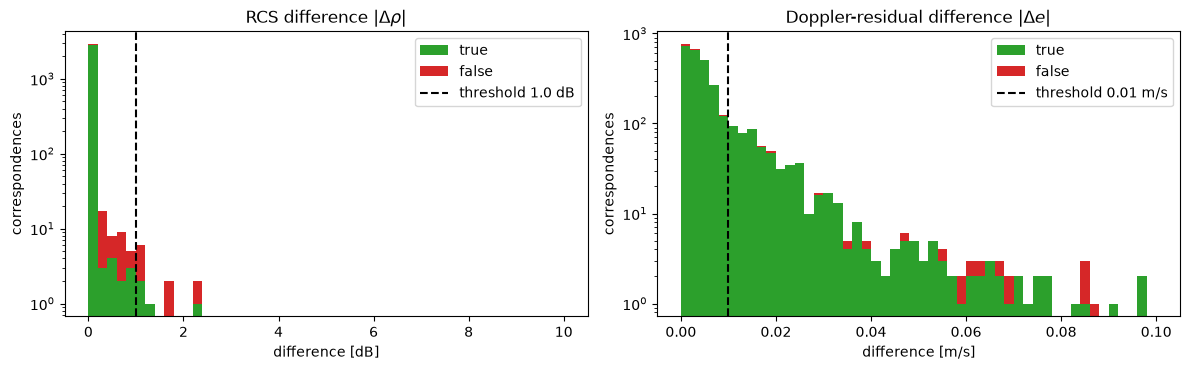

In [5]:
i, j = mutual_nearest_neighbours(source.descriptor, target.descriptor)
i_g, j_g, w_ij = doppler_rcs_gate(i, j, source, target, params)


def is_true(i, j):
    moved = source.xyz[i] @ T_gt[:3, :3].T + T_gt[:3, 3]
    return np.linalg.norm(moved - target.xyz[j], axis=1) < 0.3


true_putative = is_true(i, j)
print(f"mutual nearest neighbours  {len(i):5d}, true {100 * true_putative.mean():.1f} %")
print(f"after the gate             {len(i_g):5d}, true {100 * is_true(i_g, j_g).mean():.1f} %")

d_rcs = np.abs(source.rcs[i] - target.rcs[j])
d_res = np.abs(source.residual[i] - target.residual[j])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, d, tau, unit, bins in [(axes[0], d_rcs, params.tau_rcs, "dB", np.linspace(0, 10, 51)),
                               (axes[1], d_res, params.tau_residual, "m/s", np.linspace(0, 0.1, 51))]:
    ax.hist([d[true_putative], d[~true_putative]], bins=bins, stacked=True, log=True,
            color=["tab:green", "tab:red"], label=["true", "false"])
    ax.axvline(tau, c="k", ls="--", label=f"threshold {tau} {unit}")
    ax.set(xlabel=f"difference [{unit}]", ylabel="correspondences")
    ax.legend()
axes[0].set_title(r"RCS difference $|\Delta\rho|$")
axes[1].set_title(r"Doppler-residual difference $|\Delta e|$")
plt.tight_layout()
plt.show()

## Stages 5–6 — geometric estimate and Doppler fusion

Correspondence RANSAC with truncated-Cauchy IRLS gives the rotation $\mathbf R$ and a geometric
translation $\mathbf t_{geo}$. The two ego-velocities give a second translation,
$\mathbf t_{dop} = \tfrac12(\hat{\mathbf v}_T + \mathbf R\hat{\mathbf v}_S)\,\Delta t$, and the two
are averaged by inverse variance:
$\omega = (\sigma_v\Delta t)^{-2} / \big((\sigma_v\Delta t)^{-2} + \sigma_g^{-2}\big)$ with
$\sigma_v = 0.10$ m/s and $\sigma_g = 0.03$ m. The weight depends only on $\Delta t$: 0.93 at 12 Hz.

gated correspondences 2324, inliers 2286, fusion weight 0.957
translation [m]           x         y         z
geometric  t_geo      0.6386    0.0123   -0.0293
Doppler    t_dop      0.4884    0.0084    0.0061
DRG (fused) t         0.4949    0.0086    0.0046
ground truth          0.4847   -0.0060    0.0204
TE 0.0248 m (geometric only 0.1630 m), RE 0.186 deg


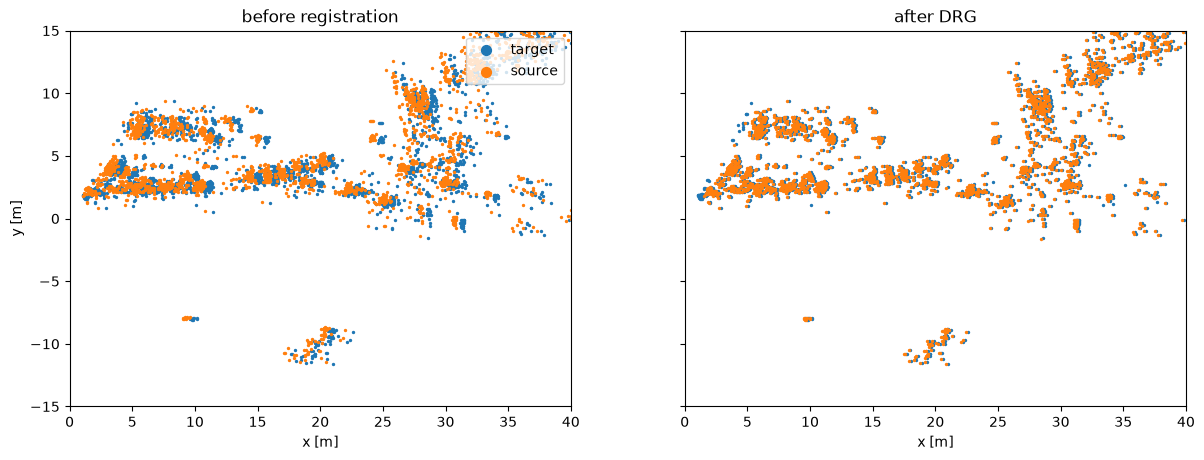

In [6]:
result = drg.register(source, target, dt)

T_geo = result.T.copy()
T_geo[:3, 3] = result.t_geo
te, re = pose_error(result.T, T_gt)
print(f"gated correspondences {result.n_gated}, inliers {result.n_inliers}, fusion weight {result.fusion_weight:.3f}")
print("translation [m]           x         y         z")
for name, t in [("geometric  t_geo", result.t_geo), ("Doppler    t_dop", result.t_dop),
                ("DRG (fused) t", result.T[:3, 3]), ("ground truth", T_gt[:3, 3])]:
    print(f"{name:18s}" + "".join(f"{v:10.4f}" for v in t))
print(f"TE {te:.4f} m (geometric only {pose_error(T_geo, T_gt)[0]:.4f} m), RE {re:.3f} deg")

aligned = scan_s[:, :3] @ result.T[:3, :3].T + result.T[:3, 3]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, src, title in [(axes[0], scan_s[:, :3], "before registration"), (axes[1], aligned, "after DRG")]:
    ax.scatter(scan_t[:, 0], scan_t[:, 1], s=2, c="tab:blue", label="target")
    ax.scatter(src[:, 0], src[:, 1], s=2, c="tab:orange", label="source")
    ax.set(xlim=(0, 40), ylim=(-15, 15), xlabel="x [m]", title=title, aspect="equal")
axes[0].set_ylabel("y [m]")
axes[0].legend(markerscale=5, loc="upper right")
plt.tight_layout()
plt.show()

## The whole window, checked against the paper

`register_pairs` is the loop used for every result of the paper: each scan is prepared once and
serves as the source of one pair and the target of the next. The estimates are compared with the
ones produced for the paper (`tests/reference/windowed_sets_seed42.json`). They agree to
floating-point rounding (about 1e-10 m; the size depends on the CPU and the numpy build).

In [7]:
pairs = list(zip(frames[:-1], frames[1:]))
rows = list(register_pairs(drg, seq, pairs, gt))

with open("../tests/reference/windowed_sets_seed42.json") as f:
    paper = {p["target"]: np.array(p["T"]) for p in json.load(f)["sets"]["loop3_set4_5692"]["pairs"]}
largest_difference = max(np.abs(r["T"] - paper[r["target"]]).max() for r in rows)

te = np.array([r["te"] for r in rows])
re = np.array([r["re"] for r in rows])
print(f"{len(rows)} pairs: mean TE {te.mean():.4f} m, mean RE {re.mean():.3f} deg "
      f"(paper, loop3 set 4: 0.0440 m, 0.133 deg)")
print(f"largest difference to the paper's estimates: {largest_difference:.1e}")
print(f"mean time per pair: {np.mean([r['time_s'] for r in rows]):.1f} s ({params.ransac_trials} RANSAC trials)")

30 pairs: mean TE 0.0440 m, mean RE 0.133 deg (paper, loop3 set 4: 0.0440 m, 0.133 deg)
largest difference to the paper's estimates: 3.1e-11
mean time per pair: 1.2 s (40 RANSAC trials)


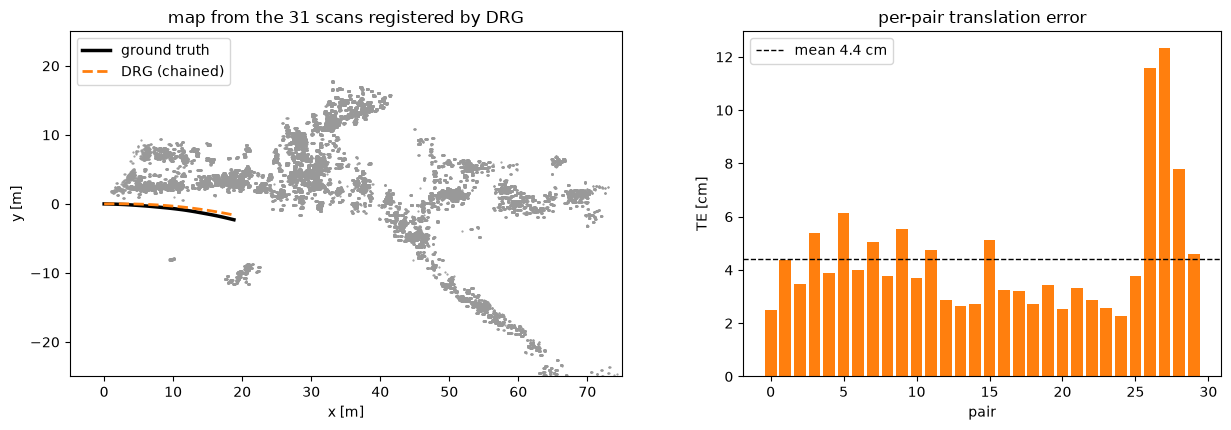

In [8]:
# Chain the estimates (P_k+1 = P_k T_k) and compare with the ground truth, both starting at the identity.
T0 = gt.pose_at(seq.stamp(frames[0]))
est, ref = [np.eye(4)], [np.eye(4)]
for r in rows:
    est.append(est[-1] @ r["T"])
    ref.append(np.linalg.inv(T0) @ gt.pose_at(r["stamp_source"]))
est, ref = np.array(est), np.array(ref)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
for k, P in zip(frames, est):
    pts = seq.points(k)
    pts = pts[np.linalg.norm(pts[:, :3], axis=1) < 60]
    xyz = pts[:, :3] @ P[:3, :3].T + P[:3, 3]
    axes[0].scatter(xyz[:, 0], xyz[:, 1], s=0.3, c="0.6")
axes[0].plot(ref[:, 0, 3], ref[:, 1, 3], "k-", lw=2.5, label="ground truth")
axes[0].plot(est[:, 0, 3], est[:, 1, 3], "--", c="tab:orange", lw=2, label="DRG (chained)")
axes[0].set(xlim=(-5, 75), ylim=(-25, 25), xlabel="x [m]", ylabel="y [m]", aspect="equal",
            title="map from the 31 scans registered by DRG")
axes[0].legend(loc="upper left")
axes[1].bar(np.arange(len(te)), 100 * te, color="tab:orange")
axes[1].axhline(100 * te.mean(), c="k", ls="--", lw=1, label=f"mean {100 * te.mean():.1f} cm")
axes[1].set(xlabel="pair", ylabel="TE [cm]", title="per-pair translation error")
axes[1].legend()
plt.tight_layout()
plt.show()

## Next steps

* Run DRG on a whole rosbag with the ROS node: see *Run on a rosbag* in the README.
* Re-score the released estimates of all 51,940 pairs (`results/relative_poses`) or re-run the
  37 windowed sets: see *Reproducing the paper* in the README.
* What every parameter does and how the tuned ones were chosen: `docs/PARAMETERS.md`.